# 03 — XGBoost baseline (tabular)

**Purpose.** Train a gradient-boosted tree on the engineered hourly table. This is the traditional-ML baseline that deep models must beat.

**Inputs.** `data/processed/tabular/{train,val,test}.parquet` from notebook 02.

**Outputs.** `models/xgboost.json`, `results/predictions_xgboost.csv`, `results/tables/metrics_xgboost.csv`, SHAP figures.


In [1]:
# Reproducible XGBoost baseline: same seed, same patient split as notebook 02.
from pathlib import Path
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

PROJECT_ROOT = Path.cwd().parent
os.environ["MPLCONFIGDIR"] = str(PROJECT_ROOT / ".mplconfig")
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    SEED, set_seed, print_library_versions, ensure_dirs, save_fig,
    classification_metrics, choose_threshold_max_f1, early_detection_metrics,
    metrics_to_row, save_metrics_table, save_predictions,
    plot_confusion_heatmap, plot_roc_pr, file_size_mb,
)

set_seed(SEED)
print("SEED =", SEED)
print_library_versions()
PATHS = ensure_dirs(PROJECT_ROOT)


SEED = 42
python 3.9.6 (default, Oct 19 2026, 19:18:13)  [Clang 21.0.0 (clang-2100.4.1.1)]
numpy        2.0.2
pandas       2.3.3
sklearn      1.6.1
xgboost      2.1.4
torch        2.8.0
shap         0.49.1
optuna       5.0.0
matplotlib   3.9.4
seaborn      0.13.2


## Class imbalance

Sepsis hours are ~2% of rows. We set `scale_pos_weight = n_negative / n_positive` on the **training** table only. That multiplies the loss of each positive hour so the booster does not ignore them. Validation and test tables are left in their natural imbalance; we never resample them.


## Load the frozen split


In [2]:
# Load the parquet tables created in notebook 02. Features already include rolling/delta columns and are scaled.
train = pd.read_parquet(PATHS["tabular"] / "train.parquet")
val = pd.read_parquet(PATHS["tabular"] / "val.parquet")
test = pd.read_parquet(PATHS["tabular"] / "test.parquet")
feature_cols = json.load(open(PATHS["processed"] / "tabular_feature_cols.json"))
print("features", len(feature_cols))
print({n: (d.shape, d.y.mean()) for n, d in [("train", train), ("val", val), ("test", test)]})
X_tr, y_tr = train[feature_cols], train["y"].astype(int)
X_va, y_va = val[feature_cols], val["y"].astype(int)
X_te, y_te = test[feature_cols], test["y"].astype(int)
pos, neg = int((y_tr==1).sum()), int((y_tr==0).sum())
spw = neg / max(pos, 1)
print("train pos", pos, "neg", neg, "scale_pos_weight", round(spw, 3))


features 180
{'train': ((382661, 183), np.float64(0.02167192371315603)), 'val': ((82478, 183), np.float64(0.021617885981716337)), 'test': ((80983, 183), np.float64(0.021905832088216046))}
train pos 8293 neg 374368 scale_pos_weight 45.143


## Model-specific EDA: engineered features


n engineered 106
top |corr| with y:
ICULOS                 0.148779
Resp_roll6_min         0.060670
Resp_roll6_mean        0.059570
FiO2_hrs_since         0.056952
Resp                   0.049341
Temp_roll6_max         0.048506
Resp_roll6_max         0.046331
HR                     0.045474
HR_roll6_max           0.045393
HR_roll6_mean          0.044617
Unit2                  0.043313
Temp                   0.042951
Phosphate_hrs_since    0.039686
FiO2_measured          0.039461
HR_roll6_min           0.039030


/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  "# 03 — XGBoost baseline (tabular)\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  "# 03 — XGBoost baseline (tabular)\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  "# 03 — XGBoost baseline (tabular)\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:8: MatplotlibDeprecationWarning: The 'labels' parameter o

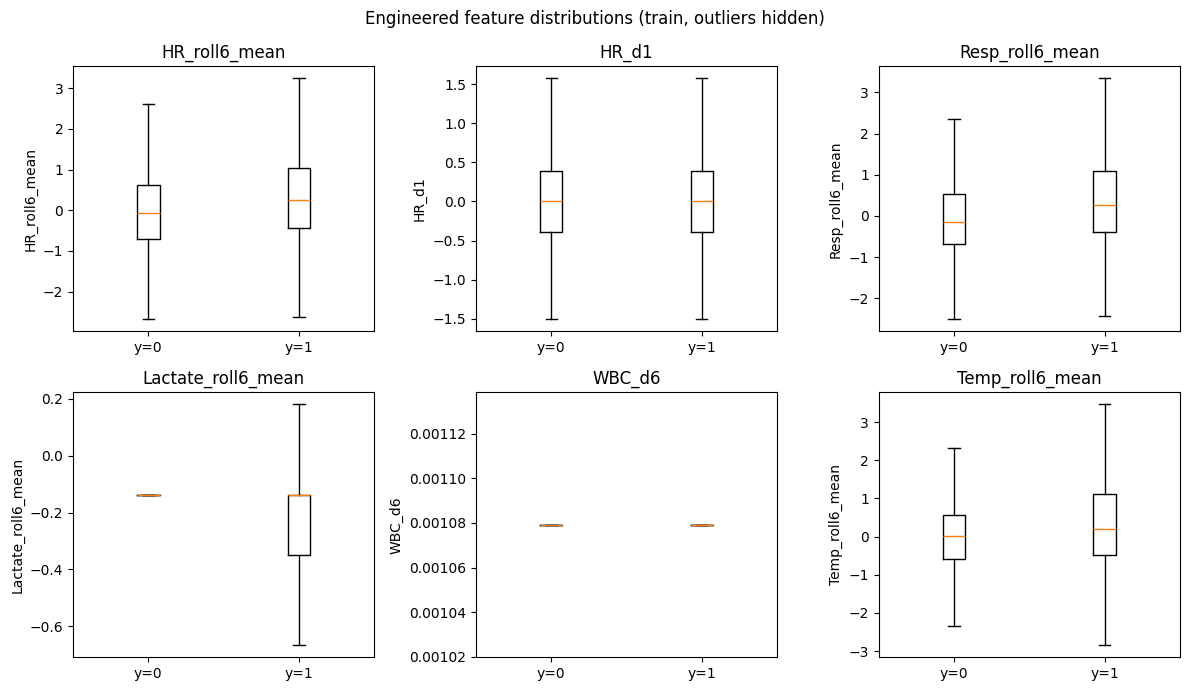

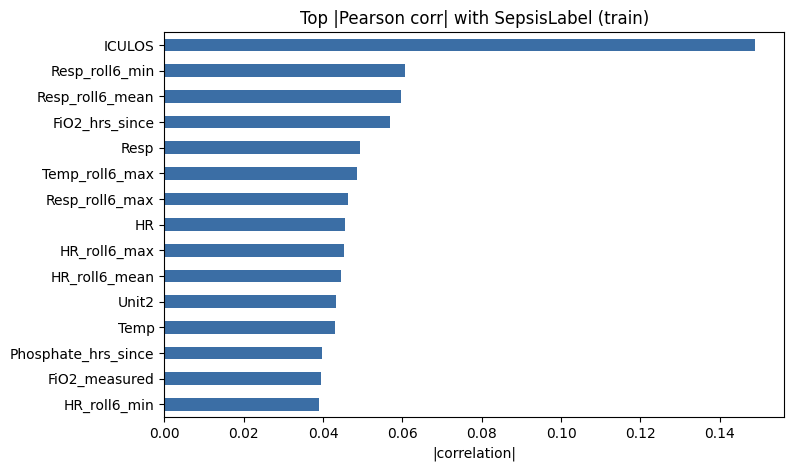

In [3]:
# Compare a few rolling/delta features on sepsis vs non-sepsis hours, and list the strongest linear correlates of the label.
eng = [c for c in feature_cols if ("_roll6_" in c or c.endswith("_d1") or c.endswith("_d6") or c.endswith("_hrs_since"))]
print("n engineered", len(eng))
show = [c for c in ["HR_roll6_mean", "HR_d1", "Resp_roll6_mean", "Lactate_roll6_mean", "WBC_d6", "Temp_roll6_mean"] if c in train.columns]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()
for ax, c in zip(axes, show):
    ax.boxplot([train.loc[train.y==0, c], train.loc[train.y==1, c]], labels=["y=0", "y=1"], showfliers=False)
    ax.set_title(c)
    ax.set_ylabel(c)
fig.suptitle("Engineered feature distributions (train, outliers hidden)")
fig.tight_layout()
save_fig(fig, PATHS["figures"] / "03_engineered_by_label.png")
plt.show()

# Pearson correlation with the label (fast screen; trees will pick up non-linear effects).
corr = train[feature_cols + ["y"]].corr(numeric_only=True)["y"].drop("y").abs().sort_values(ascending=False)
print("top |corr| with y:")
print(corr.head(15).to_string())
fig, ax = plt.subplots(figsize=(8, 5))
corr.head(15).iloc[::-1].plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_title("Top |Pearson corr| with SepsisLabel (train)")
ax.set_xlabel("|correlation|")
save_fig(fig, PATHS["figures"] / "03_top_corr.png")
plt.show()


**What we learned.** Rolling means of vitals and some lab gaps move with the label. Correlation is a weak screen only; the ablation below asks whether engineering actually helps a tree.


## Ablation: raw features vs raw + engineered (quick XGBoost)


raw 74 all 180
val PR-AUC raw only : 0.0935
val PR-AUC raw+eng  : 0.0971


/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "from sklearn.metrics import average_precision_score, roc_auc_score, f1_score\n",


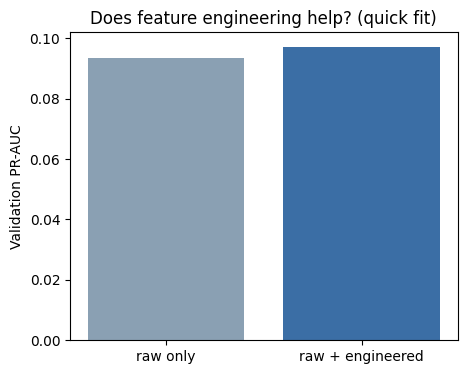

In [4]:
# Fit two small boosters on a train subsample and score PR-AUC on validation. We only want a directional answer, not a tuned model.
raw_cols = [c for c in feature_cols if not ("_roll6_" in c or c.endswith("_d1") or c.endswith("_d6") or c.endswith("_hrs_since"))]
print("raw", len(raw_cols), "all", len(feature_cols))
# Subsample train hours to keep this comparison fast.
rng = np.random.default_rng(SEED)
sub = rng.choice(len(train), size=min(80000, len(train)), replace=False)
dtrain_full_idx = train.iloc[sub]

def quick_pr(cols):
    model = xgb.XGBClassifier(
        n_estimators=80, max_depth=4, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=spw, random_state=SEED,
        n_jobs=-1, eval_metric="aucpr", early_stopping_rounds=15,
        tree_method="hist",
    )
    model.fit(
        dtrain_full_idx[cols], dtrain_full_idx["y"].astype(int),
        eval_set=[(X_va[cols], y_va)], verbose=False,
    )
    p = model.predict_proba(X_va[cols])[:, 1]
    return average_precision_score(y_va, p)

pr_raw = quick_pr(raw_cols)
pr_all = quick_pr(feature_cols)
print("val PR-AUC raw only :", round(pr_raw, 4))
print("val PR-AUC raw+eng  :", round(pr_all, 4))
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["raw only", "raw + engineered"], [pr_raw, pr_all], color=["#8aa0b3", "#3b6ea5"])
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Does feature engineering help? (quick fit)")
save_fig(fig, PATHS["figures"] / "03_raw_vs_engineered.png")
plt.show()


**What we learned.** If the engineered bar is higher, we keep the extra columns for the tuned model (they are already in `feature_cols`).


## Hyperparameter search (Optuna, ~25 trials, validation PR-AUC)


In [5]:
# Search a small, documented space. Each trial trains with early stopping on validation PR-AUC.
# We subsample train hours inside the search so 25 trials finish in reasonable time, then refit the winner on all train rows.
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
search_idx = rng.choice(len(train), size=min(120000, len(train)), replace=False)
Xs, ys = train.iloc[search_idx][feature_cols], train.iloc[search_idx]["y"].astype(int)

def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 80, 300),
        max_depth=trial.suggest_int("max_depth", 3, 7),
        learning_rate=trial.suggest_float("learning_rate", 0.03, 0.2, log=True),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 20),
        gamma=trial.suggest_float("gamma", 0.0, 3.0),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        scale_pos_weight=spw,
        random_state=SEED,
        n_jobs=-1,
        eval_metric="aucpr",
        tree_method="hist",
        early_stopping_rounds=20,
    )
    model = xgb.XGBClassifier(**params)
    model.fit(Xs, ys, eval_set=[(X_va, y_va)], verbose=False)
    p = model.predict_proba(X_va)[:, 1]
    return average_precision_score(y_va, p)

t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=25, show_progress_bar=False)
search_seconds = time.time() - t0
print("best val PR-AUC during search:", round(study.best_value, 4))
print("best params:", study.best_params)
print("search seconds:", round(search_seconds, 1))


best val PR-AUC during search: 0.1263
best params: {'n_estimators': 232, 'max_depth': 4, 'learning_rate': 0.1683730368501011, 'subsample': 0.8925495674640566, 'colsample_bytree': 0.9772836856696723, 'min_child_weight': 17, 'gamma': 1.3385649654452627, 'reg_lambda': 6.571576722573283}
search seconds: 41.8


**What we learned.** The search is scored only on validation PR-AUC. Test data is still untouched.


## Refit the best settings on all training rows


train seconds 2.4 best_iteration 39


/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "source": [


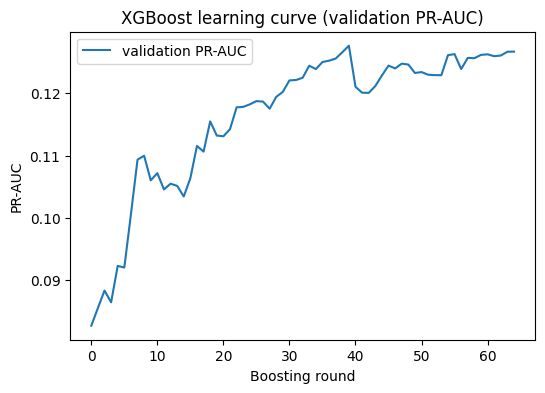

In [6]:
# Train the chosen hyperparameters on the full train table with early stopping on validation.
best = dict(study.best_params)
best.update(dict(scale_pos_weight=spw, random_state=SEED, n_jobs=-1,
                 eval_metric="aucpr", tree_method="hist", early_stopping_rounds=25))
model = xgb.XGBClassifier(**best)
t0 = time.time()
model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
train_seconds = time.time() - t0
print("train seconds", round(train_seconds, 1), "best_iteration", model.best_iteration)

# Learning curve: PR-AUC on train/val at each boosting round.
ev = model.evals_result()
# XGBoost 2 uses 'validation_0' for the first eval_set.
key = list(ev.keys())[0]
curve = ev[key]["aucpr"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curve, label="validation PR-AUC")
ax.set_title("XGBoost learning curve (validation PR-AUC)")
ax.set_xlabel("Boosting round")
ax.set_ylabel("PR-AUC")
ax.legend()
save_fig(fig, PATHS["figures"] / "03_xgb_learning_curve.png")
plt.show()


## Threshold on validation only (maximize F1)


In [7]:
# A warning system needs a 0/1 alert. We pick the cutoff that maximises F1 on validation, then freeze it for test.
p_va = model.predict_proba(X_va)[:, 1]
thr, val_m = choose_threshold_max_f1(y_va.to_numpy(), p_va)
print("chosen threshold (max F1 on val):", round(thr, 4))
print("validation metrics at that threshold:", {k: round(v, 4) if isinstance(v, float) else v for k, v in val_m.items()})


chosen threshold (max F1 on val): 0.8
validation metrics at that threshold: {'roc_auc': 0.8224, 'pr_auc': 0.128, 'precision': 0.1349, 'recall': 0.3057, 'f1': 0.1872, 'specificity': 0.9567, 'accuracy': 0.9426, 'brier': 0.1471, 'threshold': 0.8, 'tp': 545, 'fp': 3496, 'tn': 77199, 'fn': 1238, 'n': 82478, 'n_positive': 1783}


**What we learned.** The threshold is *not* tuned on test. We accept the F1-optimal cutoff; that usually balances precision and recall better than the default 0.5 on an imbalanced problem.


## Test-set evaluation


{'roc_auc': 0.8206, 'pr_auc': 0.125, 'precision': 0.1673, 'recall': 0.2909, 'f1': 0.2124, 'specificity': 0.9676, 'accuracy': 0.9528, 'brier': 0.143, 'threshold': 0.8, 'tp': 516, 'fp': 2568, 'tn': 76641, 'fn': 1258, 'n': 80983, 'n_positive': 1774}
early detection: {'n_sepsis_patients': 186, 'pct_detected': 45.69892473118279, 'pct_detected_6h_before': 30.64516129032258, 'edt_mean_hours': 38.023529411764706, 'edt_median_hours': 19.0, 'false_alarms_per_patient_day': 0.7780933984774457, 'n_detected': 85}
saved model, predictions, metrics


/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ]
/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  {


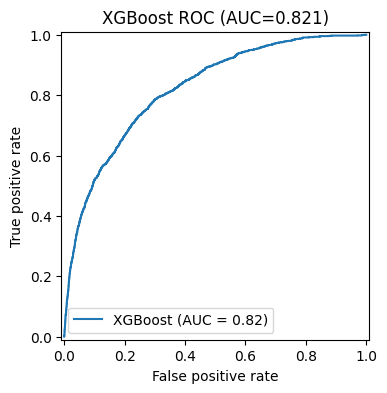

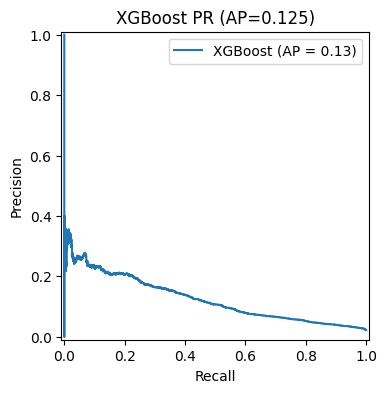

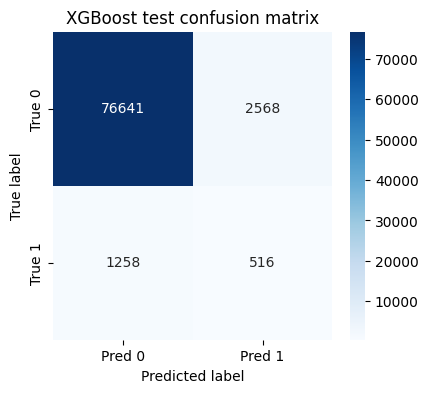

In [8]:
# Score the held-out patients. This is the only number that counts as "final" for XGBoost.
t1 = time.time()
p_te = model.predict_proba(X_te)[:, 1]
infer_seconds = time.time() - t1
metrics = classification_metrics(y_te.to_numpy(), p_te, thr)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()})

pred_path = PATHS["results"] / "predictions_xgboost.csv"
save_predictions(test["patient_id"], test["hour"], y_te, p_te, pred_path)
pred_df = pd.read_csv(pred_path)
edt, edt_detail = early_detection_metrics(pred_df, "patient_id", "hour", threshold=thr)
print("early detection:", edt)

plot_roc_pr(y_te, p_te, "XGBoost", PATHS["figures"] / "03_xgb_roc.png", PATHS["figures"] / "03_xgb_pr.png")
plt.show()
plot_confusion_heatmap(metrics, "XGBoost test confusion matrix", PATHS["figures"] / "03_xgb_cm.png")
plt.show()

model_path = PATHS["models"] / "xgboost.json"
model.save_model(model_path)
joblib.dump({"threshold": thr, "feature_cols": feature_cols, "best_params": best}, PATHS["models"] / "xgboost_meta.joblib")

extra = dict(
    train_seconds=train_seconds, infer_seconds=infer_seconds, search_seconds=search_seconds,
    n_params=int(model.get_booster().num_boosted_rounds()),
    model_mb=file_size_mb(model_path),
    **{f"edt_{k}": v for k, v in edt.items() if k != "n_sepsis_patients"},
    n_sepsis_patients=edt["n_sepsis_patients"],
)
save_metrics_table(metrics_to_row("xgboost", metrics, extra), PATHS["tables"] / "metrics_xgboost.csv")
print("saved model, predictions, metrics")


**Onset note.** Early detection time uses the first hour with `y_true=1` as onset. PhysioNet already shifted labels earlier than bedside diagnosis, so a positive EDT means "alerted before the *label* flipped," not necessarily before a clinician would notice.


## SHAP explanations


explained test row 1136 patient 373.0 hour 141.0 p 0.87549686


/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  "**Purpose.** Train a gradient-boosted tree on the engineered hourly table. This is the traditional-ML baseline that deep models must beat.\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "**Outputs.** `models/xgboost.json`, `results/predictions_xgboost.csv`, `results/tables/metrics_xgboost.csv`, SHAP figures.\n"
/Users/shaikniyaz/projects/CSET343_project/notebooks/03_model_xgboost.ipynb:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new

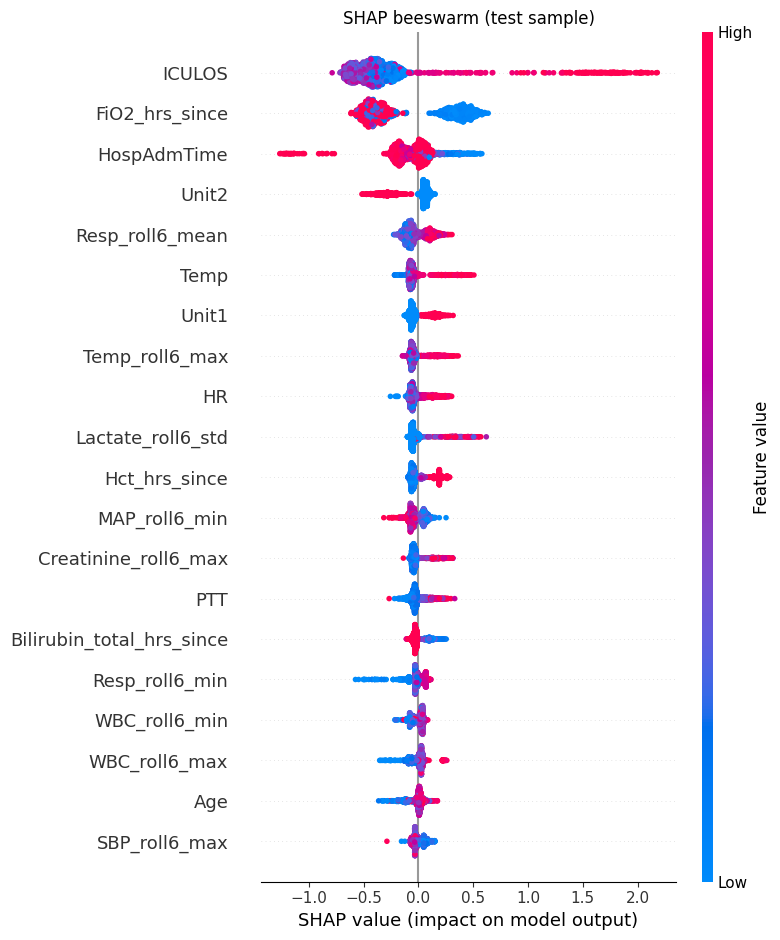

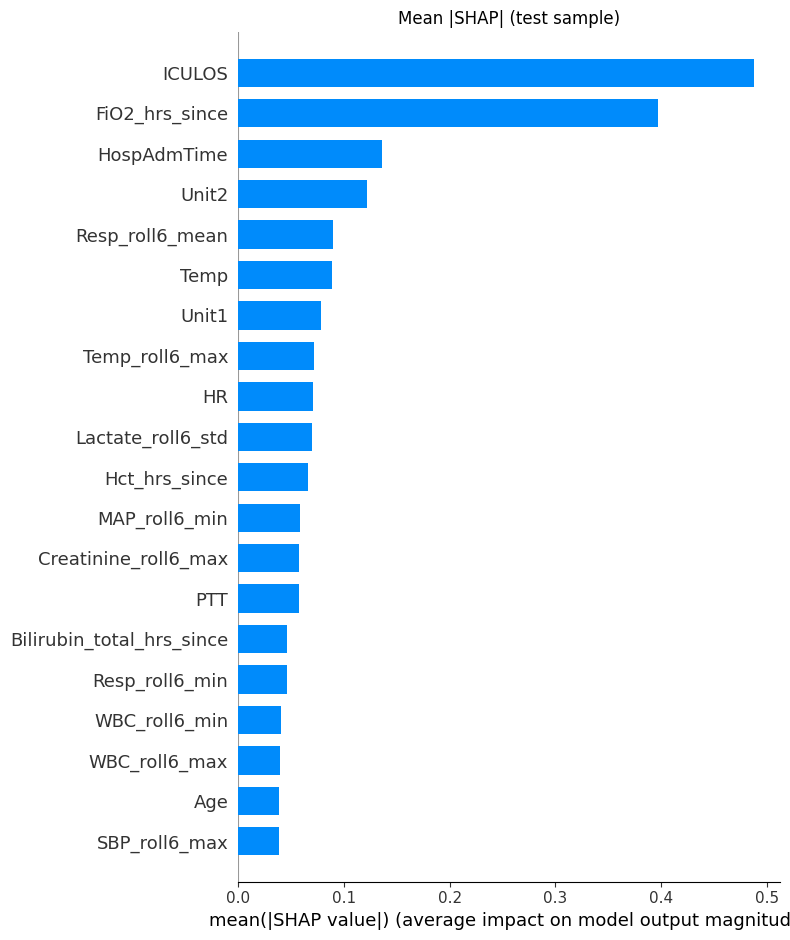

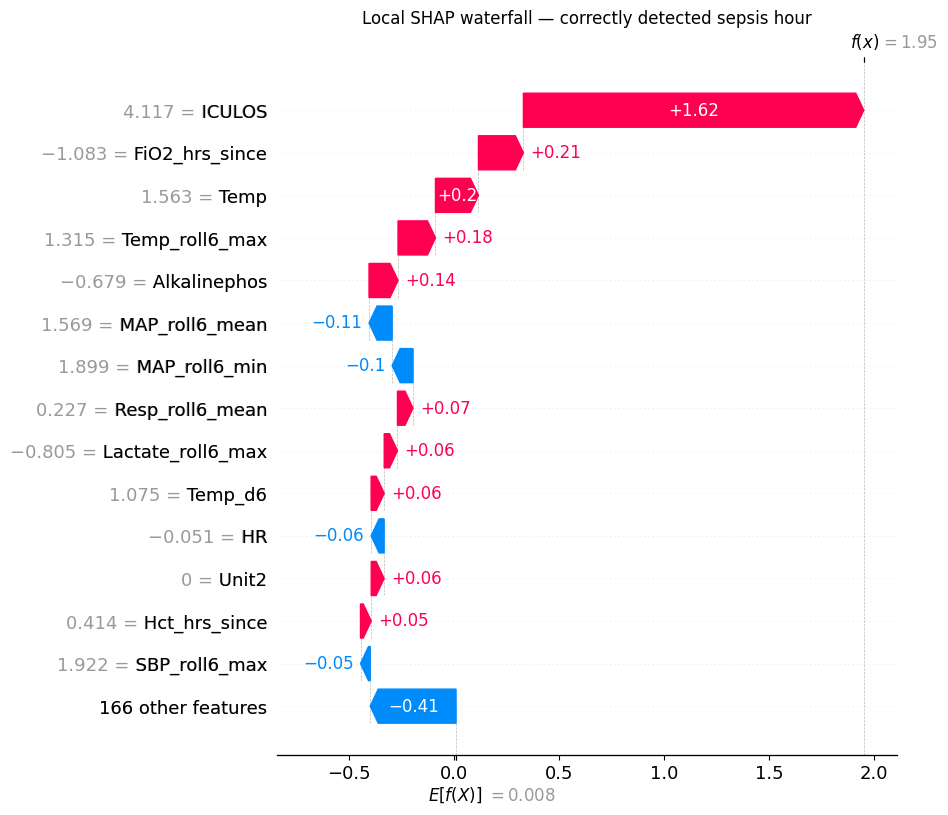

In [9]:
# TreeExplainer is exact for gradient-boosted trees. We explain a sample of test hours (full test SHAP would be slow).
rng = np.random.default_rng(SEED)
sample_n = min(2000, len(test))
sidx = rng.choice(len(test), size=sample_n, replace=False)
X_s = X_te.iloc[sidx]
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_s)

plt.figure()
shap.summary_plot(shap_values, X_s, show=False, max_display=20)
plt.title("SHAP beeswarm (test sample)")
plt.tight_layout()
save_fig(plt.gcf(), PATHS["figures"] / "03_shap_beeswarm.png")
plt.show()

plt.figure()
shap.summary_plot(shap_values, X_s, plot_type="bar", show=False, max_display=20)
plt.title("Mean |SHAP| (test sample)")
plt.tight_layout()
save_fig(plt.gcf(), PATHS["figures"] / "03_shap_bar.png")
plt.show()

# Local explanation: one correctly detected sepsis hour (true=1 and prob >= threshold).
hit = np.where((y_te.to_numpy()==1) & (p_te >= thr))[0]
if len(hit) == 0:
    hit = np.where(y_te.to_numpy()==1)[0]
row_i = int(hit[0])
sv_one = explainer.shap_values(X_te.iloc[[row_i]])
exp = shap.Explanation(
    values=sv_one[0],
    base_values=float(np.array(explainer.expected_value).reshape(-1)[0]),
    data=X_te.iloc[row_i].to_numpy(),
    feature_names=feature_cols,
)
plt.figure()
shap.plots.waterfall(exp, max_display=15, show=False)
plt.title("Local SHAP waterfall — correctly detected sepsis hour")
save_fig(plt.gcf(), PATHS["figures"] / "03_shap_waterfall.png")
plt.show()
print("explained test row", row_i, "patient", test.iloc[row_i]["patient_id"], "hour", test.iloc[row_i]["hour"], "p", p_te[row_i])


**How to read the SHAP plots.**
- **Beeswarm:** each dot is one hour. Color is the feature value; position is how much it pushed the prediction toward sepsis (right) or away (left).
- **Bar:** average absolute push per feature — a global importance ranking.
- **Waterfall:** for one hour, starting from the average log-odds, each arrow is one feature's contribution to that hour's score.


### Notebook 03 summary


In [10]:
# Recap the headline test metrics for this baseline.
print(pd.read_csv(PATHS["tables"] / "metrics_xgboost.csv").T)
print("Done with notebook 03.")


                                          0
model                               xgboost
roc_auc                            0.820639
pr_auc                             0.125013
precision                          0.167315
recall                             0.290868
f1                                 0.212433
specificity                        0.967579
accuracy                           0.952756
brier                              0.143016
threshold                               0.8
tp                                      516
fp                                     2568
tn                                    76641
fn                                     1258
n                                     80983
n_positive                             1774
train_seconds                       2.39252
infer_seconds                      0.033836
search_seconds                    41.787267
n_params                                 65
model_mb                              0.134
edt_pct_detected                